In [3]:
# ---------------------------------------------------------------------
# 0. Import Libraries
# ---------------------------------------------------------------------
import sys
import os
import warnings
import numpy
import scipy
import matplotlib
import sklearn
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, minimize
from scipy.spatial.distance import pdist
from scipy.stats import rankdata, norm, spearmanr, qmc
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C

warnings.filterwarnings("ignore")
SEED = 42

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# Figures Colors and settings
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [4]:
# ---------------------------------------------------------------------
# 1. Load the data
# ---------------------------------------------------------------------
X = np.load('..\Function_1_Data\Week_13_Data/F1_Week_13_inputs.npy')
y = np.load('..\Function_1_Data\Week_13_Data/F1_Week_13_outputs.npy')
n = len(y)
N_INITIAL = 10
W12 = n - 1                       # row 21: the week-12 query (newest reading)
W11 = n - 2                       # row 20: the week-11 query (previous best)

inc = int(np.argmax(y))
L = np.log10(np.abs(y))
BEST = y[inc]
print(f"n = {n}, best row = {inc}, best y = {BEST:.6g}, previous best = {np.max(y[:W12]):.6g}")

n = 22, best row = 21, best y = 1.9634, previous best = 1.80382


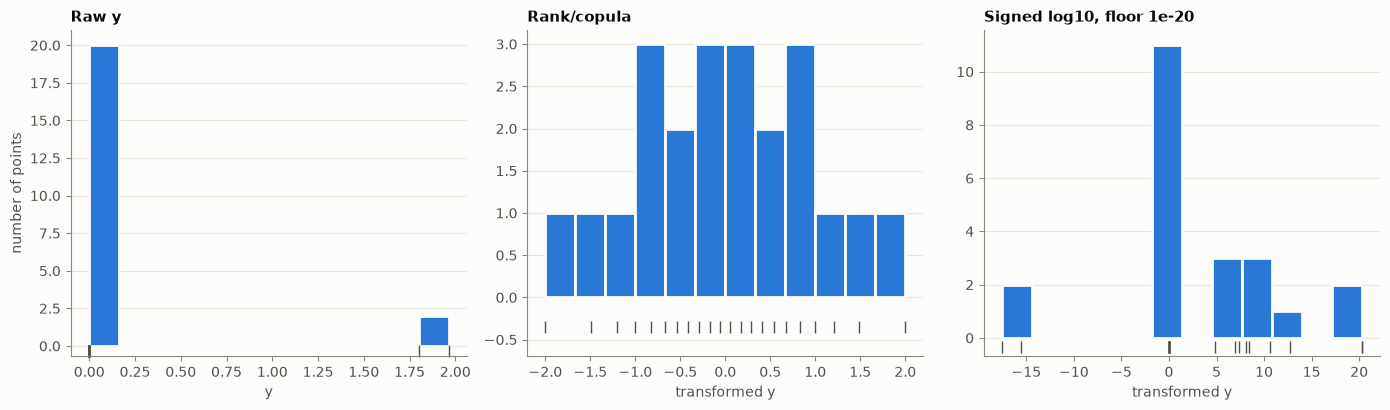

In [5]:
# ---------------------------------------------------------------------
# 2. Re-apply rank-based copula and signed log transforms to all points
# ---------------------------------------------------------------------
def copula(v):
    return norm.ppf((rankdata(v, method="average") - 0.5) / len(v))

FLOOR = -20.0
def signed_log(v):
    return np.sign(v) * np.maximum(np.log10(np.abs(v)) - FLOOR, 0.0)

targets = {"rank/copula": copula(y), "signed log10": signed_log(y)}

# ---------------------------------------------------------------------
# Fig 1: target distributions
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (title, vals, xl) in zip(axes, [("Raw y", y, "y"),
                                        ("Rank/copula", targets["rank/copula"], "transformed y"),
                                        ("Signed log10, floor 1e-20", targets["signed log10"], "transformed y")]):
    ax.hist(vals, bins=12, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.plot(vals, np.full(n, -0.35), "|", color=INK2, markersize=9, clip_on=False)
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylim(bottom=-0.7); ax.grid(axis="x", visible=False)
axes[0].ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
axes[0].set_ylabel("number of points")
fig.tight_layout()


SURROGATES (Matern 5/2, one length-scale per input, bounds 0.02-2.0)
  rank/copula  : length-scales x1=0.0200 x2=0.0200 (on a bound: ['x1', 'x2'])  LOO RMSE/std=0.767  Spearman=0.671  95% coverage=0.91
  signed log10 : length-scales x1=0.0310 x2=0.0238 (on a bound: none)  LOO RMSE/std=0.692  Spearman=0.591  95% coverage=0.91
  rank/copula  : LOO for the newest row 21: actual +2.00, predicted +1.45 +/- 0.24
  signed log10 : LOO for the newest row 21: actual +20.29, predicted +20.08 +/- 1.52


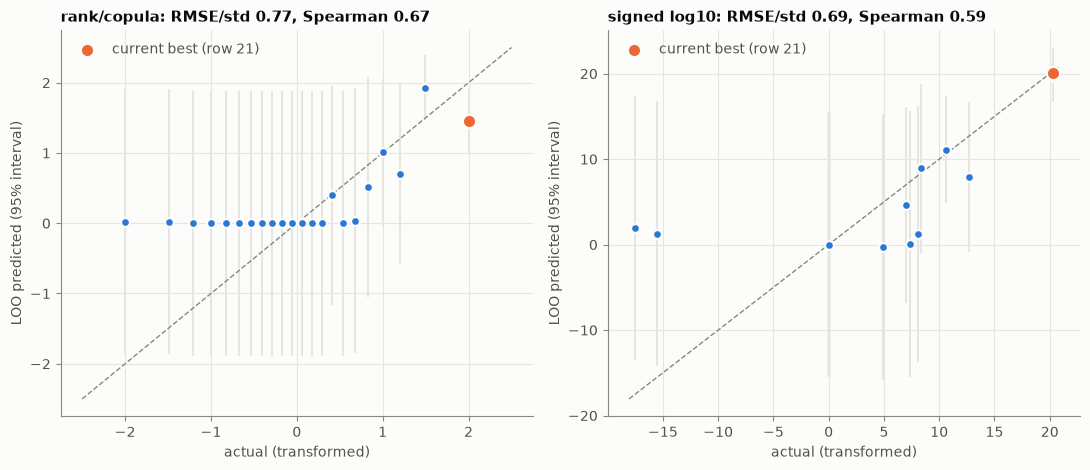

In [6]:
# ---------------------------------------------------------------------
# 3. Refit Matern 5/2 ARD GP on all points and perform LOO-CV
# ---------------------------------------------------------------------
def fit_gp(t):
    init = [np.median(pdist(X[:, [j]])) for j in range(2)]
    k = C(1.0, (1e-2, 1e2)) * Matern(length_scale=init, length_scale_bounds=(0.02, 2.0), nu=2.5)
    return GaussianProcessRegressor(kernel=k, alpha=1e-6, n_restarts_optimizer=15, random_state=SEED).fit(X, t)

def loo(gp, t):
    mu, sd = np.empty(n), np.empty(n)
    for i in range(n):
        keep = np.arange(n) != i
        g = GaussianProcessRegressor(kernel=gp.kernel_, alpha=1e-6, optimizer=None).fit(X[keep], t[keep])
        a, b = g.predict(X[i:i + 1], return_std=True)
        mu[i], sd[i] = a[0], b[0]
    return mu, sd

gps, loos = {}, {}
print("\nSURROGATES (Matern 5/2, one length-scale per input, bounds 0.02-2.0)")
for name, t in targets.items():
    gps[name] = fit_gp(t)
    loos[name] = loo(gps[name], t)
    mu, sd = loos[name]
    ls = gps[name].kernel_.k2.length_scale
    on_bound = [f"x{j + 1}" for j, v_ in enumerate(ls) if np.isclose(v_, 0.02, rtol=1e-3) or np.isclose(v_, 2.0, rtol=1e-3)]
    print(f"  {name:13s}: length-scales x1={ls[0]:.4f} x2={ls[1]:.4f} (on a bound: {on_bound or 'none'})  "
          f"LOO RMSE/std={np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}  "
          f"Spearman={spearmanr(t, mu)[0]:.3f}  95% coverage={np.mean(np.abs((t - mu) / sd) < 1.96):.2f}")
for name, t in targets.items():
    print(f"  {name:13s}: LOO for the newest row {W12}: actual {t[W12]:+.2f}, predicted {loos[name][0][W12]:+.2f} "
          f"+/- {loos[name][1][W12]:.2f}")

# ---------------------------------------------------------------------
# Fig 2: LOO CV (GP cross-check)
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, name in zip(axes, targets):
    t = targets[name]; mu, sd = loos[name]
    lim = [min(t.min(), mu.min()) - 0.5, max(t.max(), mu.max()) + 0.5]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.errorbar(t, mu, yerr=1.96 * sd, fmt="none", ecolor=GRID, elinewidth=1.5, zorder=1)
    ax.scatter(t, mu, s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.scatter(t[inc], mu[inc], s=90, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=4,
               label=f"current best (row {inc})")
    ax.set_title(f"{name}: RMSE/std {np.sqrt(np.mean((t - mu) ** 2)) / t.std():.2f}, "
                 f"Spearman {spearmanr(t, mu)[0]:.2f}")
    ax.set_xlabel("actual (transformed)"); ax.set_ylabel("LOO predicted (95% interval)")
    ax.legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.tight_layout()


In [7]:
# ---------------------------------------------------------------------
# 4. Fit a Gaussian bump gives log10|y| = a - k * |x - c|^2 near the isolated peak.
# ---------------------------------------------------------------------
def env(p, Z):
    a, k, c1, c2 = p
    return a - k * ((Z[:, 0] - c1) ** 2 + (Z[:, 1] - c2) ** 2)

X0 = (0.3, 700, 0.626, 0.628)
def fit_env(rows, x0=X0):
    rows = list(rows)
    p = least_squares(lambda q: env(q, X[rows]) - L[rows], x0).x
    jack = np.array([least_squares(lambda q, T=[j for j in rows if j != i]: env(q, X[T]) - L[T], x0).x for i in rows])
    return p, jack

FAR = [2, 13, 16, 18, 19]                      # positive flank points
NEG = [4, 17]                                  # negative readings, used as |y|
SETS = {
    "week-12 6-positive (rows 2,13,16,18,19,20)": FAR + [W11],
    "week-12 8-point (adds rows 4, 17)": FAR + [W11] + NEG,
    "7 positive (adds row 21)": FAR + [W11, W12],
    "9 points (adds rows 4, 17)": FAR + [W11, W12] + NEG,
    "near-peak 5 (rows 4, 17, 19, 20, 21)": [4, 17, 19, W11, W12],
}
fits = {}
print("\nENVELOPE MODELS  log10|y| = a - k*|x - c|^2")
for name, rows in SETS.items():
    p, jack = fit_env(rows)
    fits[name] = (rows, p, jack)
    res = env(p, X[rows]) - L[rows]
    print(f"  {name}")
    print(f"    a={p[0]:.4f} k={p[1]:.1f} centre=({p[2]:.6f}, {p[3]:.6f}) peak |y|~{10 ** p[0]:.4f} "
          f"width={np.sqrt(np.log10(np.e) / (2 * p[1])):.4f}  rms resid={np.sqrt(np.mean(res ** 2)):.4f} decades "
          f"({len(rows)} points, {len(rows) - 4} dof)")
    print(f"    leave-one-out centres: x1 {jack[:, 2].min():.4f}-{jack[:, 2].max():.4f}, "
          f"x2 {jack[:, 3].min():.4f}-{jack[:, 3].max():.4f}")

p_w12_6 = fits["week-12 6-positive (rows 2,13,16,18,19,20)"][1]
p_w12_8 = fits["week-12 8-point (adds rows 4, 17)"][1]
p_pos7 = fits["7 positive (adds row 21)"][1]
p_all9 = fits["9 points (adds rows 4, 17)"][1]
p_close = fits["near-peak 5 (rows 4, 17, 19, 20, 21)"][1]
jack_close = fits["near-peak 5 (rows 4, 17, 19, 20, 21)"][2]

print(f"\nWEEK-12 PREDICTIONS of the newest reading (log10 y observed = {L[W12]:+.4f}, y = {y[W12]:.4f}; "
      f"week-11 best was {y[W11]:.4f})")
pred_w12 = {}
for nm, p in [("week-12 6-positive fit", p_w12_6), ("week-12 8-point fit", p_w12_8)]:
    e = env(p, X[W12:W12 + 1])[0]
    pred_w12[nm] = e
    print(f"  {nm}: predicted log10 y = {e:+.3f} (y ~ {10 ** e:.3f}); error observed - predicted = {L[W12] - e:+.3f} decades")
print(f"  week-12 recommended point was (0.626081, 0.629823); the queried point is ({X[W12, 0]:.6f}, {X[W12, 1]:.6f})")


ENVELOPE MODELS  log10|y| = a - k*|x - c|^2
  week-12 6-positive (rows 2,13,16,18,19,20)
    a=0.3245 k=712.1 centre=(0.623146, 0.632700) peak |y|~2.1113 width=0.0175  rms resid=0.0957 decades (6 points, 2 dof)
    leave-one-out centres: x1 0.6000-0.6300, x2 0.6259-0.6526
  week-12 8-point (adds rows 4, 17)
    a=0.2046 k=710.8 centre=(0.629016, 0.626947) peak |y|~1.6017 width=0.0175  rms resid=0.1496 decades (8 points, 4 dof)
    leave-one-out centres: x1 0.6254-0.6295, x2 0.6257-0.6283
  7 positive (adds row 21)
    a=0.3156 k=711.6 centre=(0.623073, 0.632754) peak |y|~2.0684 width=0.0175  rms resid=0.0888 decades (7 points, 3 dof)
    leave-one-out centres: x1 0.6081-0.6300, x2 0.6259-0.6457
  9 points (adds rows 4, 17)
    a=0.2362 k=712.7 centre=(0.628976, 0.627007) peak |y|~1.7226 width=0.0175  rms resid=0.1437 decades (9 points, 5 dof)
    leave-one-out centres: x1 0.6256-0.6295, x2 0.6258-0.6281
  near-peak 5 (rows 4, 17, 19, 20, 21)
    a=0.3044 k=746.8 centre=(0.626597, 0.62


LEAVE-ONE-OUT INSIDE THE NEAR-PEAK SET (fit on the other four rows, predict the held-out one)
  hold out row  4: predicted log10|y| = -2.695, actual -2.443, error -0.252 decades; centre without it = (0.6256, 0.6242), k = 775
  hold out row 17: predicted log10|y| = -4.421, actual -4.488, error +0.067 decades; centre without it = (0.6272, 0.6252), k = 745
  hold out row 19: predicted log10|y| = -7.376, actual -7.266, error -0.110 decades; centre without it = (0.6274, 0.6254), k = 752
  hold out row 20: predicted log10|y| = +0.260, actual +0.256, error +0.004 decades; centre without it = (0.6266, 0.6256), k = 747
  hold out row 21: predicted log10|y| = +0.289, actual +0.293, error -0.004 decades; centre without it = (0.6266, 0.6256), k = 746

HOW WELL EACH FIT FAMILY PREDICTS THE TWO NEWEST ROWS (fitted without the row being predicted)
  flank-based (rows 2,13,16,18,19)     + row 21: predicts row 20 at +0.370 (actual +0.256), error +0.114 decades
  flank-based (rows 2,13,16,18,19)     + 

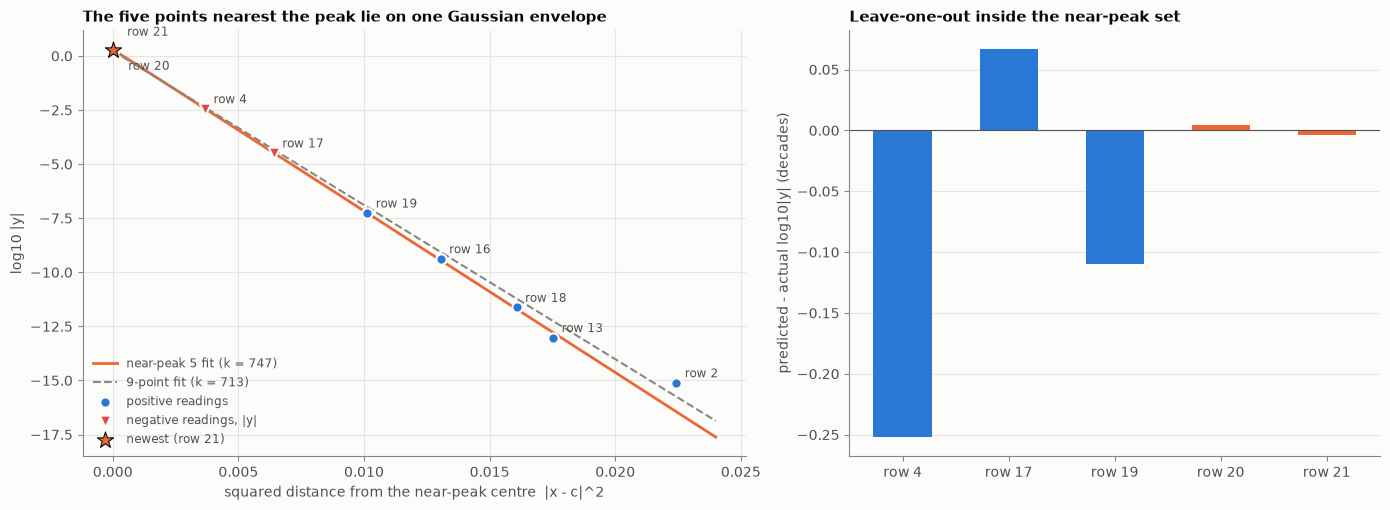

In [8]:
# ---------------------------------------------------------------- validation inside the near-peak set
print("\nLEAVE-ONE-OUT INSIDE THE NEAR-PEAK SET (fit on the other four rows, predict the held-out one)")
close_rows = SETS["near-peak 5 (rows 4, 17, 19, 20, 21)"]
loo_close = {}
for i in close_rows:
    T = [j for j in close_rows if j != i]
    p = least_squares(lambda q: env(q, X[T]) - L[T], X0).x
    e = env(p, X[i:i + 1])[0]
    loo_close[i] = (e, L[i], p)
    print(f"  hold out row {i:2d}: predicted log10|y| = {e:+.3f}, actual {L[i]:+.3f}, error {e - L[i]:+.3f} decades; "
          f"centre without it = ({p[2]:.4f}, {p[3]:.4f}), k = {p[1]:.0f}")

# the same test for the older, flank-based fits, on the two newest rows
print("\nHOW WELL EACH FIT FAMILY PREDICTS THE TWO NEWEST ROWS (fitted without the row being predicted)")
fam_err = {}
for fam, base_rows in [("flank-based (rows 2,13,16,18,19)", FAR), ("flank + negatives", FAR + NEG), ("near-peak (rows 4,17,19)", [4, 17, 19])]:
    for tgt, extra in [(W11, [W12]), (W12, [W11])]:
        T = base_rows + extra
        p = least_squares(lambda q: env(q, X[T]) - L[T], X0).x
        e = env(p, X[tgt:tgt + 1])[0]
        fam_err[(fam, tgt)] = e - L[tgt]
        print(f"  {fam:36s} + row {extra[0]}: predicts row {tgt} at {e:+.3f} (actual {L[tgt]:+.3f}), error {e - L[tgt]:+.3f} decades")

centre_close = p_close[2:]
r_c = np.linalg.norm(X - centre_close, axis=1)
print("\nSign check around the near-peak centre (distance, sign, residual vs the near-peak envelope):")
for i in np.argsort(r_c):
    if r_c[i] < 0.15:
        print(f"    row {i:2d}  r = {r_c[i]:.4f}  {'+' if y[i] > 0 else '-'}  y = {y[i]:+.3e}  "
              f"residual = {L[i] - env(p_close, X[i:i+1])[0]:+.3f} decades")
print(f"  flank rows against the near-peak fit (envelope - actual, decades): "
      + ", ".join(f"row {i}: {env(p_close, X[i:i+1])[0] - L[i]:+.2f}" for i in FAR if i != 19))


# ---------------------------------------------------------------------
# Fig 3: envelope fits and the near-peak validation
# ---------------------------------------------------------------------
d2c = np.sum((X - centre_close) ** 2, axis=1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
grid = np.linspace(0, 0.024, 50)
ax.plot(grid, p_close[0] - p_close[1] * grid, color=ORANGE, lw=2, label=f"near-peak 5 fit (k = {p_close[1]:.0f})")
ax.plot(grid, p_all9[0] - p_all9[1] * grid, color=MUTED, lw=1.5, ls="--", label=f"9-point fit (k = {p_all9[1]:.0f})")
pos_pts = [i for i in FAR + [W11, W12]]
ax.scatter(d2c[pos_pts], L[pos_pts], s=55, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3, label="positive readings")
ax.scatter(d2c[NEG], L[NEG], s=70, marker="v", color=RED, edgecolor=SURFACE, linewidth=1.5, zorder=3, label="negative readings, |y|")
ax.scatter(d2c[W12], L[W12], s=150, marker="*", color=ORANGE, edgecolor=INK, linewidth=0.8, zorder=4, label="newest (row 21)")
for i in FAR + [W11, W12] + NEG:
    off = {W12: (10, 10), W11: (10, -14)}.get(i, (6, 4))
    ax.annotate(f"row {i}", (d2c[i], L[i]), xytext=off, textcoords="offset points", fontsize=8.5, color=INK2)
ax.set_xlabel("squared distance from the near-peak centre  |x - c|^2")
ax.set_ylabel("log10 |y|")
ax.set_title("The five points nearest the peak lie on one Gaussian envelope")
ax.legend(frameon=False, loc="lower left", labelcolor=INK2, fontsize=8.5)
ax = axes[1]
rows_l = list(loo_close)
ax.bar(range(len(rows_l)), [loo_close[i][0] - loo_close[i][1] for i in rows_l], color=[ORANGE if i in (W11, W12) else BLUE for i in rows_l], width=0.55)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(range(len(rows_l))); ax.set_xticklabels([f"row {i}" for i in rows_l])
ax.set_ylabel("predicted - actual log10|y| (decades)")
ax.set_title("Leave-one-out inside the near-peak set")
ax.grid(axis="x", visible=False)
fig.tight_layout()
print('\n')

In [9]:
# ---------------------------------------------------------------------
# Candidates and regret table
# ---------------------------------------------------------------------
gp_c = gps["rank/copula"]
f_best = targets["rank/copula"].max()
def ei(Z, xi=0.0):
    mu, s = gp_c.predict(Z, return_std=True)
    s = np.maximum(s, 1e-12)
    z = (mu - f_best - xi) / s
    return (mu - f_best - xi) * norm.cdf(z) + s * norm.pdf(z)

S = np.vstack([qmc.Sobol(2, seed=1).random(2 ** 14), X])
v = ei(S)
x_ei, best_ei = S[v.argmax()], v.max()
for x0 in S[np.argsort(-v)[:15]]:
    r = minimize(lambda x: -ei(x[None])[0], x0, bounds=[(0, 1)] * 2, method="L-BFGS-B")
    if -r.fun > best_ei:
        x_ei, best_ei = r.x, -r.fun
print(f"\nGP-EI (week-12 kernel family) maximum EI = {best_ei:.4g} at ({x_ei[0]:.6f}, {x_ei[1]:.6f})")

cands = {
    "A: near-peak 5 envelope centre": centre_close,
    "B: 7-positive envelope centre": p_pos7[2:],
    "C: 9-point envelope centre": p_all9[2:],
    "D: mean of the 7-positive and near-peak centres": 0.5 * (p_pos7[2:] + centre_close),
    "E: GP-EI (copula, xi=0)": x_ei,
    "F: best observed point (row 21)": X[inc],
}
scen = {"near-peak 5": p_close, "7 positive": p_pos7, "9 points": p_all9}
print("\nCANDIDATES: predicted y at each candidate if each fit were the truth (best observed y = %.4f)" % BEST)
regret = {}
for name, xc in cands.items():
    mu_c, sd_c = gp_c.predict(xc[None], return_std=True)
    vals = {s_: 10 ** env(p, xc[None])[0] for s_, p in scen.items()}
    regret[name] = vals
    print(f"  {name:48s} x = ({xc[0]:.6f}, {xc[1]:.6f})  dist to best = {np.linalg.norm(xc - X[inc]):.4f}  "
          + "  ".join(f"{s_}: {v_:.3f}" for s_, v_ in vals.items())
          + f"   GP copula {mu_c[0]:+.2f} +/- {sd_c[0]:.2f}")
print("  (a fit whose own peak is below the observed best is contradicted by the data:")
for s_, p in scen.items():
    print(f"     {s_}: peak {10 ** p[0]:.3f}, prediction at row 21 {10 ** env(p, X[inc:inc + 1])[0]:.3f} vs observed {BEST:.3f}")
print("  )")
xs_close = centre_close
print(f"\nNear-peak envelope: query at its centre ({xs_close[0]:.6f}, {xs_close[1]:.6f}); predicted y = {10 ** p_close[0]:.4f}; "
      f"distance from row 21 = {np.linalg.norm(xs_close - X[inc]):.4f}")
# sensitivity of the prediction at the chosen point to the centre uncertainty (jackknife centres)
loss = [10 ** (p_close[0] - p_close[1] * np.sum((xs_close - c) ** 2)) for c in jack_close[:, 2:]]
print(f"  predicted y at the query if the true centre were each leave-one-out centre: "
      f"{min(loss):.4f} to {max(loss):.4f} (peak value varies too; k fixed at {p_close[1]:.0f})")
for i, (e, a_, p) in loo_close.items():
    val = 10 ** (p[0] - p[1] * np.sum((xs_close - p[2:]) ** 2))
    print(f"  loss check, centre/k/a from the fit without row {i}: y at the query = {val:.4f}")


GP-EI (week-12 kernel family) maximum EI = 0.4027 at (0.630556, 0.623541)

CANDIDATES: predicted y at each candidate if each fit were the truth (best observed y = 1.9634)
  A: near-peak 5 envelope centre                   x = (0.626597, 0.625618)  dist to best = 0.0042  near-peak 5: 2.015  7 positive: 1.865  9 points: 1.701   GP copula +2.28 +/- 0.18
  B: 7-positive envelope centre                    x = (0.623073, 0.632754)  dist to best = 0.0042  near-peak 5: 1.807  7 positive: 2.068  9 points: 1.541   GP copula +1.46 +/- 0.03
  C: 9-point envelope centre                       x = (0.628976, 0.627007)  dist to best = 0.0040  near-peak 5: 1.989  7 positive: 1.851  9 points: 1.723   GP copula +2.32 +/- 0.13
  D: mean of the 7-positive and near-peak centres  x = (0.624835, 0.629186)  dist to best = 0.0014  near-peak 5: 1.961  7 positive: 2.015  9 points: 1.662   GP copula +1.97 +/- 0.08
  E: GP-EI (copula, xi=0)                          x = (0.630556, 0.623541)  dist to best = 0.0077  

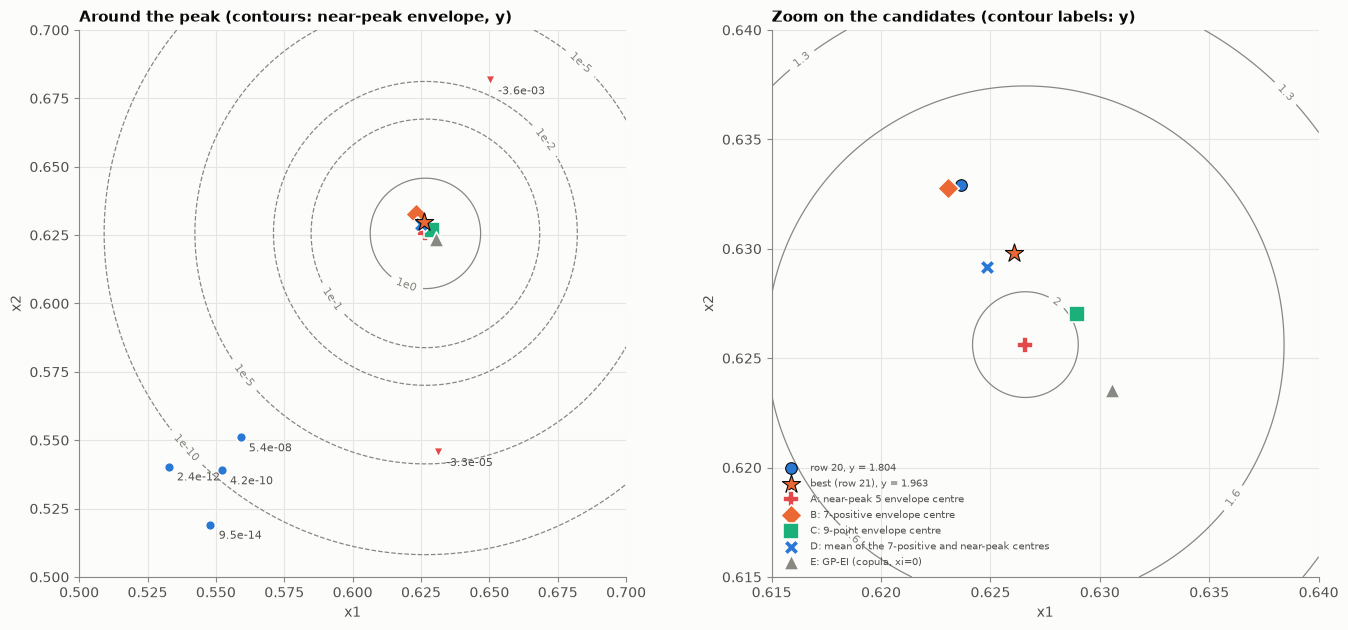

In [10]:
# ---------------------------------------------------------------------
# Fig 4: map with candidates (left: around the peak, right: zoom)
# ---------------------------------------------------------------------
marks = {"A: near-peak 5 envelope centre": ("P", RED), "B: 7-positive envelope centre": ("D", ORANGE),
         "C: 9-point envelope centre": ("s", AQUA), "D: mean of the 7-positive and near-peak centres": ("X", BLUE),
         "E: GP-EI (copula, xi=0)": ("^", MUTED)}
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
for ax, (lo, hi, levels, zoom) in zip(axes, [(0.50, 0.70, [-10, -5, -2, -1, 0], False),
                                              (0.615, 0.640, [-0.5, -0.3, -0.1, 0.0, 0.1, 0.2, 0.3], True)]):
    g1 = np.linspace(lo, hi, 200)
    G1, G2 = np.meshgrid(g1, g1)
    E = env(p_close, np.column_stack([G1.ravel(), G2.ravel()])).reshape(G1.shape)
    cs = ax.contour(G1, G2, E, levels=levels, colors=MUTED, linewidths=0.9)
    ax.clabel(cs, fmt=(lambda v_: f"{10 ** v_:.2g}") if zoom else (lambda v_: f"1e{int(v_)}"), fontsize=8)
    if not zoom:
        inside = np.all((X >= lo) & (X <= hi), axis=1)
        for i in np.where(inside)[0]:
            col = RED if y[i] < 0 else BLUE
            ax.scatter(*X[i], s=55, color=col, edgecolor=SURFACE, linewidth=1.5, zorder=3,
                       marker="v" if y[i] < 0 else "o")
            if i not in (W11, W12):
                ax.annotate(f"{y[i]:.1e}", X[i], xytext=(6, -10), textcoords="offset points", fontsize=8, color=INK2)
    ax.scatter(*X[W11], s=70, color=BLUE, edgecolor=INK, linewidth=0.8, zorder=5, label=f"row {W11}, y = {y[W11]:.3f}")
    ax.scatter(*X[inc], s=190, marker="*", color=ORANGE, edgecolor=INK, linewidth=0.8, zorder=6,
               label=f"best (row {inc}), y = {BEST:.3f}")
    for name, xc in cands.items():
        if name in marks:
            m, c = marks[name]
            ax.scatter(*xc, s=120, marker=m, color=c, edgecolor=SURFACE, linewidth=1.2, zorder=5, label=name)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_aspect("equal"); ax.set_xlabel("x1"); ax.set_ylabel("x2")
axes[0].set_title("Around the peak (contours: near-peak envelope, y)")
axes[1].set_title("Zoom on the candidates (contour labels: y)")
axes[1].legend(frameon=False, loc="lower left", fontsize=7.5, labelcolor=INK2)
fig.tight_layout()

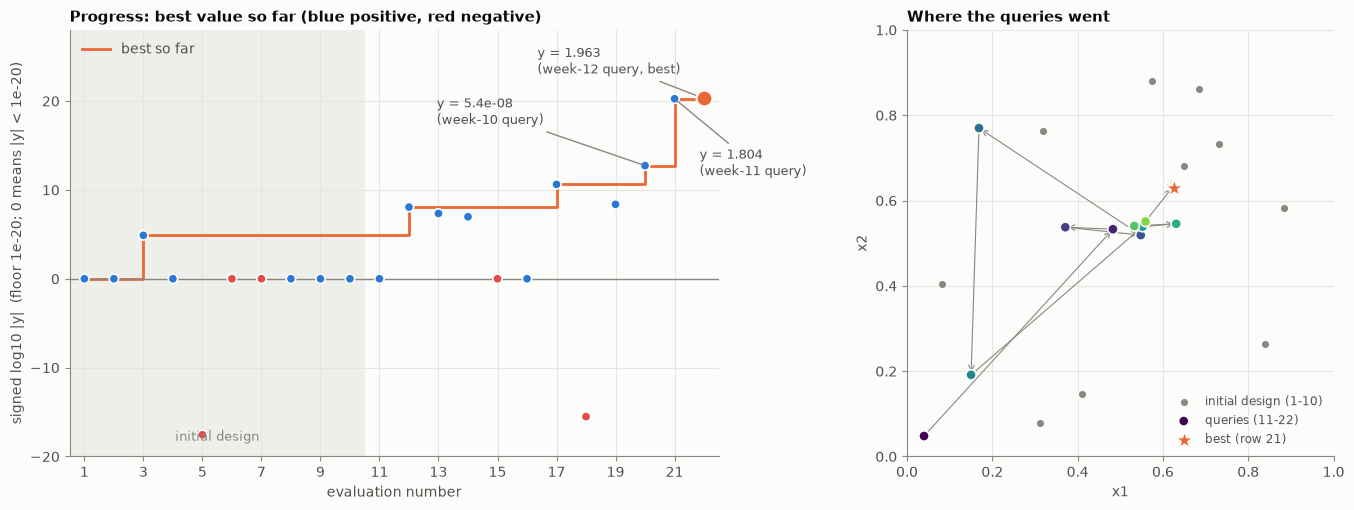

In [11]:
# ---------------------------------------------------------------------
# Fig 5: progress
# ---------------------------------------------------------------------
sl = signed_log(y)
best_sofar = np.maximum.accumulate(y)
bs_sl = signed_log(best_sofar)
idx = np.arange(1, n + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ax.axvspan(0.5, N_INITIAL + 0.5, color=GRID, alpha=0.6, lw=0)
ax.step(idx, bs_sl, where="post", color=ORANGE, lw=2, label="best so far")
colors = [RED if v_ < 0 else BLUE for v_ in y]
ax.scatter(idx, sl, c=colors, s=45, edgecolor=SURFACE, linewidth=1.2, zorder=3)
ax.scatter(idx[inc], sl[inc], s=130, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=4)
ax.axhline(0, color=MUTED, lw=1)
ax.annotate(f"y = {y[W12]:.3f}\n(week-12 query, best)", (idx[W12], sl[W12]), xytext=(-120, 18),
            textcoords="offset points", fontsize=9, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set_ylim(-20, 28)
ax.annotate(f"y = {y[W11]:.3f}\n(week-11 query)", (idx[W11], sl[W11]), xytext=(18, -55),
            textcoords="offset points", fontsize=9, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.annotate(f"y = {y[19]:.1e}\n(week-10 query)", (idx[19], sl[19]), xytext=(-150, 30),
            textcoords="offset points", fontsize=9, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.text(N_INITIAL / 2 + 0.5, 0.03, "initial design", ha="center", va="bottom",
        transform=ax.get_xaxis_transform(), fontsize=9, color=MUTED)
ax.set_xticks(idx[::2]); ax.set_xlim(0.5, n + 0.5)
ax.set_xlabel("evaluation number"); ax.set_ylabel("signed log10 |y|  (floor 1e-20; 0 means |y| < 1e-20)")
ax.set_title("Progress: best value so far (blue positive, red negative)")
ax.legend(frameon=False, loc="upper left", labelcolor=INK2)

ax = axes[1]
ax.scatter(X[:N_INITIAL, 0], X[:N_INITIAL, 1], s=40, color=MUTED, edgecolor=SURFACE, linewidth=1.2,
           zorder=3, label=f"initial design (1-{N_INITIAL})")
q = np.arange(N_INITIAL, n)
sc = ax.scatter(X[q, 0], X[q, 1], s=55, c=np.arange(len(q)), cmap="viridis", edgecolor=SURFACE,
                linewidth=1.2, zorder=4, label=f"queries ({N_INITIAL + 1}-{n})")
for a_, b_ in zip(q[:-1], q[1:]):
    ax.annotate("", xy=X[b_], xytext=X[a_], arrowprops=dict(arrowstyle="->", color=MUTED, lw=0.8), zorder=2)
ax.scatter(*X[inc], s=170, marker="*", color=ORANGE, edgecolor=SURFACE, linewidth=1, zorder=5, label=f"best (row {inc})")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title("Where the queries went")
ax.legend(frameon=False, loc="lower right", fontsize=8.5, labelcolor=INK2)
fig.tight_layout()